# Export AoA figures

Run [AOA_Paper.ipynb](AOA_Paper.ipynb) first. This notebook uses its saved `experiment.json`, replays the same calculation, and verifies that the DD values and branches match before exporting.

The complete publication set is **1. fractional DD, 2. ephemeris AoA, 3. proposed DD AoA, 4. side-by-side comparison**. Diagnostic plots are exported in separate subfolders.


In [1]:
from pathlib import Path
from aoa_figure_report import (
    FIGURE_STEMS, combined_report_section, export_combined_windows, export_saved_experiment, load_figure_design,
)


## 1. Choose the completed run and destination

`EXPERIMENT_RUN` is either one `experiment.json` or a run folder whose `window_*/experiment.json` files are exported side by side. `DISPLAY_DURATION_S` fixes the time axis at 0–120 s (the first 120 s of a longer window; a shorter one leaves the rest empty); `None` uses every analysis-window epoch. The defaults keep all authentic PRNs. Optional presentation filters are kept here, separate from the experiment.


In [2]:
EXPERIMENT_RUN = Path('/Users/betty/Developer/research/angle/outputs/aoa_experiments/sp-partial-28-09/v2-prior90')
EXPORT_DIR = Path('/Users/betty/Desktop/AOA_Figures_sp-partial-28-09/v2-prior90')
FORMATS = ('png', 'pdf', 'eps')
INCLUDE_DIAGNOSTICS = True

COMPACT_EPOCHS = None
DISPLAY_DURATION_S = 120  # fixed 0-120 s manuscript axis; None shows the whole window
EXTEND_AUTHENTIC = True  # a shorter window: authentic PRNs continue to 120 s, spoof PRNs end with the window
AUTHENTIC_MAX_ERROR_DEG = None  # None: only the unfiltered table, which lists every clean PRN in the figures
FILTER_FIGURES = False  # True also drops the excluded PRNs from the figures


## 2. Export

Figure style is stored in `aoa_figure_style.json`. Figure 3 preserves every valid DD estimate, including PRNs without ephemeris geometry. Figure 4 uses paired observations in both panels. Missing values are never interpolated. Each export folder gets a `report.txt` (spoof PRNs, reference satellite, branch selection, results); a run with several windows also gets a combined `report.txt` at the top. With several windows, `combined/` repeats Figures 1–4 with every window on one capture-time axis; the interval between windows is left blank.


=== window_01 -> /Users/betty/Desktop/AOA_Figures_sp-partial-28-09/v2-prior90/window_01


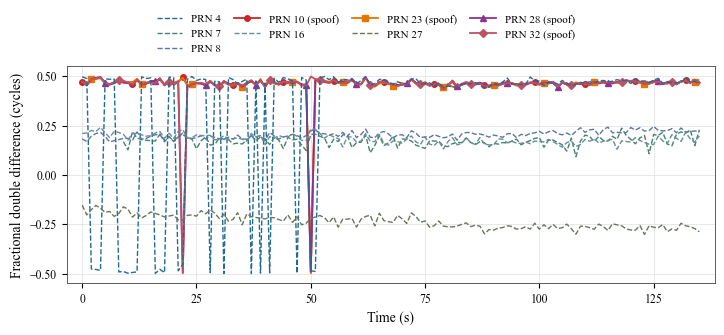

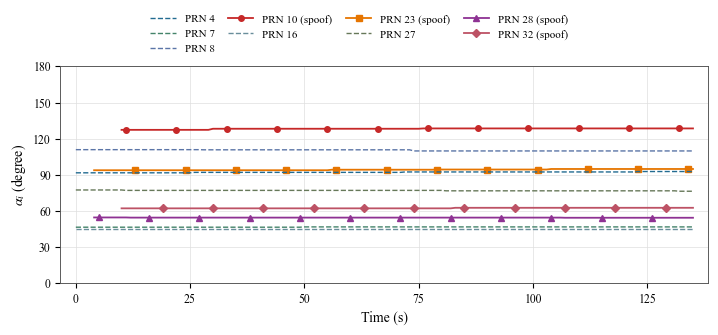

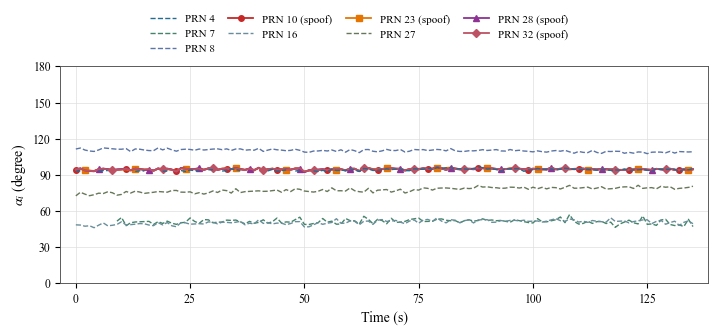

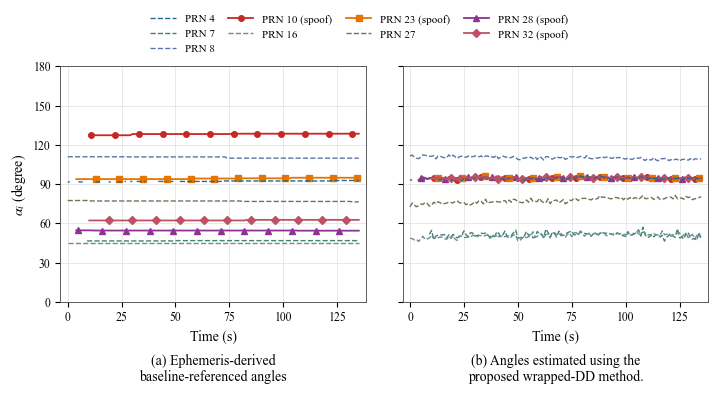

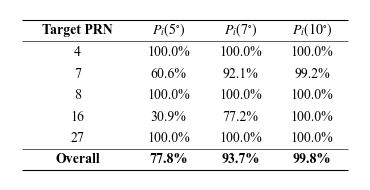

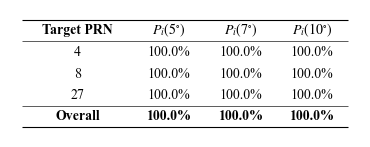

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


...

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


=== window_02 -> /Users/betty/Desktop/AOA_Figures_sp-partial-28-09/v2-prior90/window_02


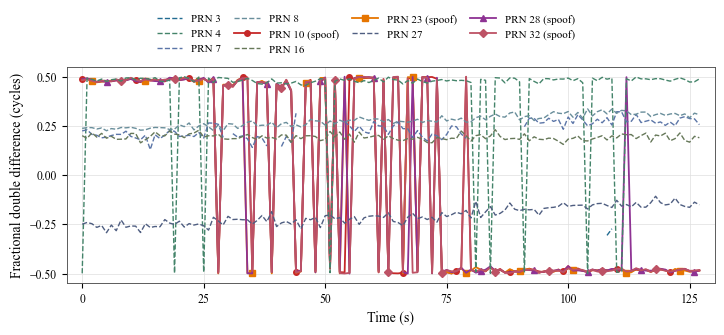

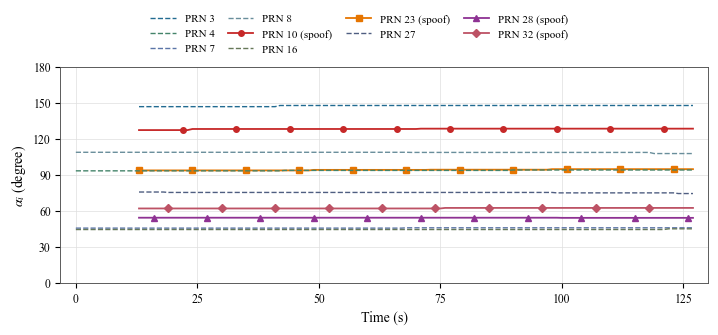

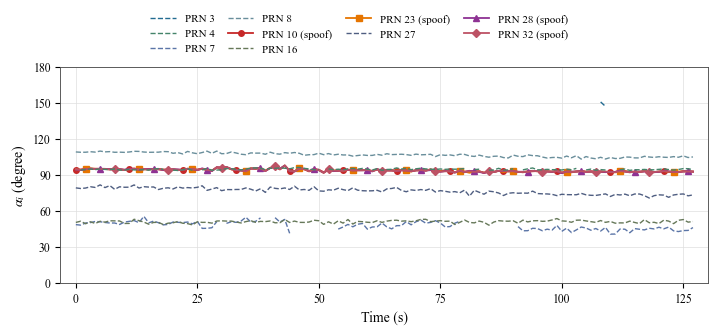

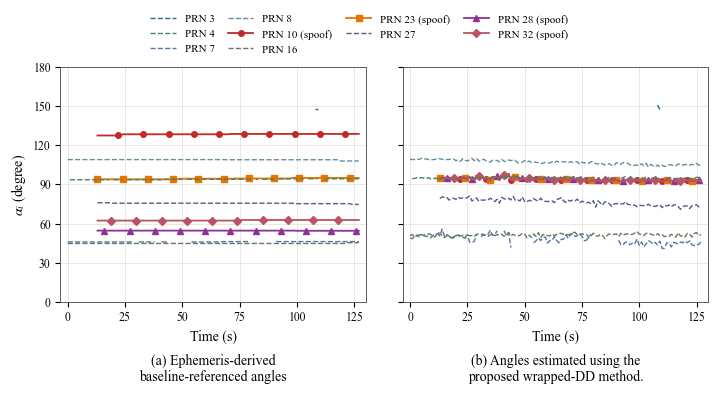

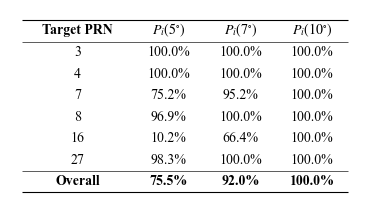

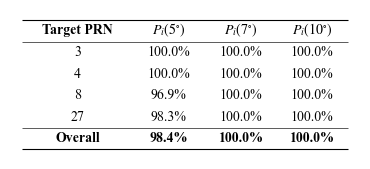

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


...

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


=== combined windows


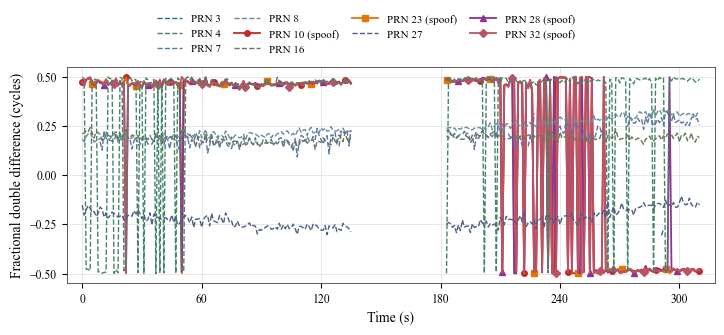

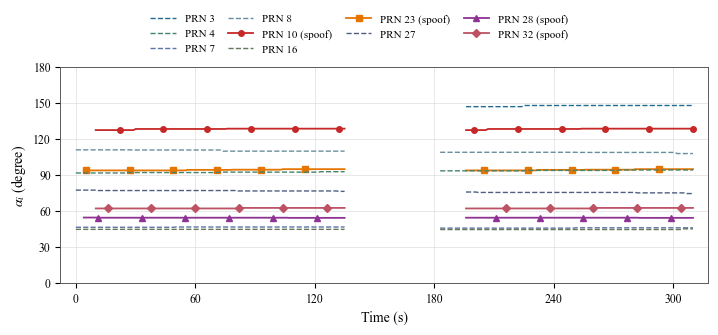

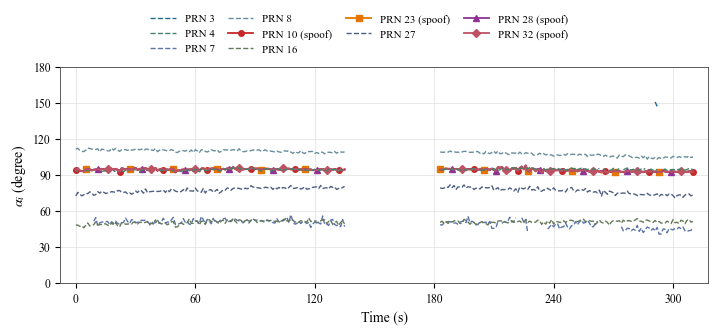

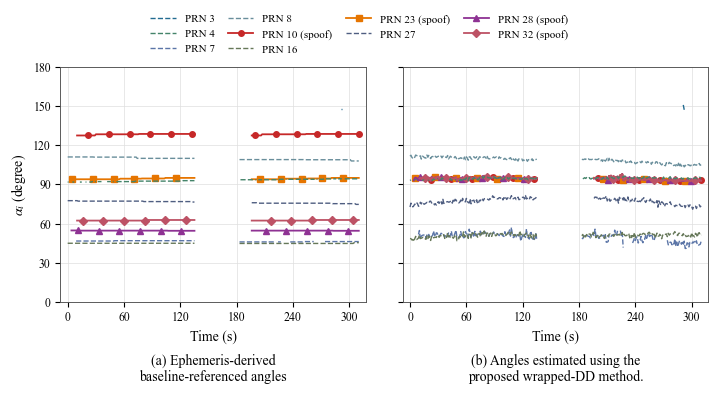

Combined figures (all windows on one capture-time axis)
Folder: /Users/betty/Desktop/AOA_Figures_sp-partial-28-09/v2-prior90/combined
Time axis: seconds since GPS TOW 124414 (first window start). The gap between windows is left blank; no values are interpolated.
  window_01: t = 0-135 s, capture epochs 0-135 (TOW 124414-124549, 136 epochs), reference PRN 9, chosen_by prior, spoof-group AoA 94.81 deg
  window_02: t = 183-310 s, capture epochs 151-278 (TOW 124597-124724, 128 epochs), reference PRN 9, chosen_by prior, spoof-group AoA 93.64 deg


AoA export report: sp-partial-28-09/v2-prior90/window_01
Created (UTC):        2026-09-29T06:11:50.532758+00:00
Experiment file:      /Users/betty/Developer/research/angle/outputs/aoa_experiments/sp-partial-28-09/v2-prior90/window_01/experiment.json
Replay verified:      yes

Capture
  Dataset dir:        /Users/betty/Developer/research/angle/dataset/sp-partial-28-09/90
  Receiver 1:         COM3___9600_260928_103310.ubx
  Receiver 2:         COM4

In [3]:
if EXPERIMENT_RUN.is_file():
    jobs = {EXPORT_DIR: EXPERIMENT_RUN}
else:
    jobs = {EXPORT_DIR / path.parent.name: path for path in sorted(EXPERIMENT_RUN.glob('window_*/experiment.json'))}
assert jobs, f"No experiment.json under {EXPERIMENT_RUN}"

design = load_figure_design()
design["formats"] = list(FORMATS)
reports = {}
for destination, experiment_file in jobs.items():
    print(f"=== {experiment_file.parent.name} -> {destination}")
    reports[destination] = export_saved_experiment(
        experiment_file,
        destination,
        design=design,
        compact_epochs=COMPACT_EPOCHS,
        display_duration_s=DISPLAY_DURATION_S,
        extend_authentic=EXTEND_AUTHENTIC,
        authentic_max_error_deg=AUTHENTIC_MAX_ERROR_DEG,
        filter_figures=FILTER_FIGURES,
        include_diagnostics=INCLUDE_DIAGNOSTICS,
        show=True,
    )
combined = None
if len(jobs) > 1:
    print("=== combined windows")
    combined = export_combined_windows(list(jobs), EXPORT_DIR / "combined", design=design, show=True)
    (EXPORT_DIR / "report.txt").write_text(
        "\n\n".join([combined_report_section(combined), *((destination / "report.txt").read_text() for destination in jobs)]),
        encoding="utf-8",
    )
print((EXPORT_DIR / "report.txt").read_text() if (EXPORT_DIR / "report.txt").is_file() else "")


## 3. Verify the files

The publication figures appear above. Each destination also contains plotted CSVs, branch alternatives, a source manifest, `report.txt`, and the optional full-window diagnostics.


In [4]:
for destination, report in reports.items():
    expected = [destination / f"{stem}.{extension}" for stem in FIGURE_STEMS for extension in FORMATS]
    assert len(report["figure_files"]) == len(expected)
    assert all(path.is_file() and path.stat().st_size > 0 for path in expected)
    assert (destination / "report.txt").is_file()
    suffixes = ["unfiltered"] + (["filtered"] if AUTHENTIC_MAX_ERROR_DEG is not None else [])
    assert all((destination / f"table_01_authentic_angular_agreement_{suffix}.tex").is_file() for suffix in suffixes)
    assert report["experiment_replay_verified"]
    print(f"{destination.name}: publication figures {report['figure_count']}; diagnostic figures {report['diagnostic_figure_count']}; "
          f"total figure files {report['total_figure_file_count']}")
if combined is not None:
    assert len(combined["figure_files"]) == len(FIGURE_STEMS) * len(FORMATS)
    print(f"combined: {len(combined['window_segments'])} windows, {len(combined['figure_files'])} figure files")
print(f"Saved to: {EXPORT_DIR}")


window_01: publication figures 4; diagnostic figures 21; total figure files 75
window_02: publication figures 4; diagnostic figures 21; total figure files 75
combined: 2 windows, 12 figure files
Saved to: /Users/betty/Desktop/AOA_Figures_sp-partial-28-09/v2-prior90
